# 03 — Quan hệ giữa các biến (Relationships)

**Mục tiêu:** tìm mối liên hệ giữa giá, số lượng, chi phí mua, doanh thu, biên lợi nhuận, phí
vận chuyển và tồn kho — ở 3 cấp: **sản phẩm**, **nhà cung cấp (NCC)**, **cửa hàng / thời gian**.

| Truy vấn | Cấp | Câu hỏi |
|---|---|---|
| `vendor_brand` | NCC × sản phẩm | Giá ↔ lượng bán? Mua ↔ bán? Biên ↔ phân khúc giá? |
| `vendor_kpi`, `top_vendors` | NCC | Doanh thu tập trung đến mức nào? Quy mô ↔ biên, phí vận chuyển? |
| `sales_vs_purchases_monthly` | tháng | Mua hàng có đi trước/sau mùa bán? |
| `store_performance`, `store_month_sales` | cửa hàng | Tồn kho ↔ doanh thu? Mùa vụ có khác giữa cửa hàng? |
| `po_metrics` | PO | Quy mô đơn ↔ tỷ lệ phí vận chuyển, lead time? |

## 0. Thiết lập môi trường
Thêm thư mục gốc dự án vào `sys.path` để import package `src`, nạp thư viện và áp dụng
phong cách biểu đồ xuất bản (bảng màu **đậm**) dùng chung cho mọi notebook.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl, preprocessing as pp, visualization as viz
from src.config import TABLE_DIR
from src.visualization import PALETTE, CLASS_COLORS

viz.set_style()
TABLE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Nạp dữ liệu
Toàn bộ là bảng tổng hợp (≤ 11 nghìn dòng) → nạp gần như tức thì.

In [2]:
vb = dl.query("vendor_brand", min_purchase=0)
vendors = dl.query("vendor_kpi", min_sales=0)
po = dl.query("po_metrics")
stores = dl.query("store_performance")
monthly = dl.query("sales_vs_purchases_monthly")
{k: len(v) for k, v in dict(vb=vb, vendors=vendors, po=po, stores=stores, monthly=monthly).items()}

{'vb': 11450, 'vendors': 129, 'po': 5543, 'stores': 80, 'monthly': 12}

## 2. Ma trận tương quan cấp sản phẩm

**Biểu đồ 3.1 — Tương quan Spearman** (dựa trên hạng → bền với phân phối lệch phải và ngoại lai)
giữa các chỉ tiêu của `mart_vendor_brand`. Đỏ đậm = tương quan âm, xanh navy = tương quan dương.

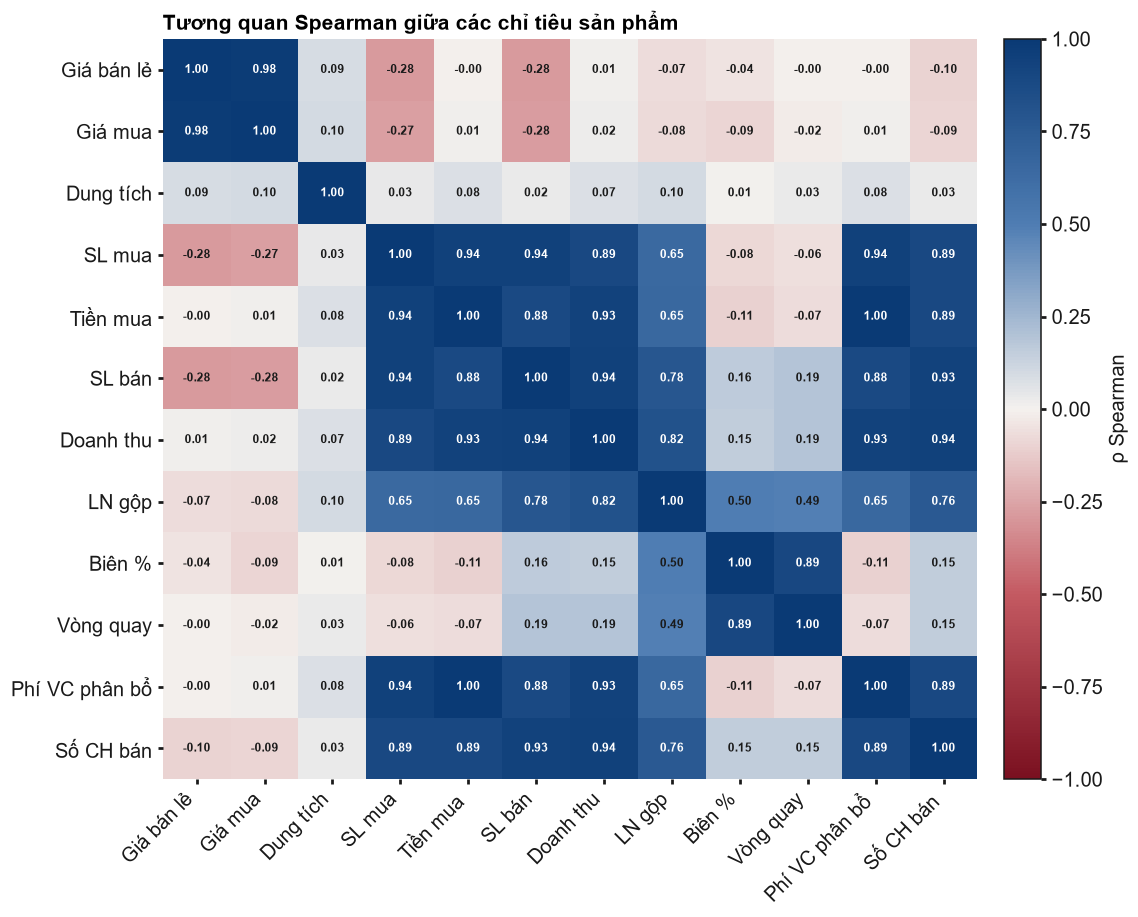

In [3]:
cols = {"RetailPrice": "Giá bán lẻ", "PurchasePrice": "Giá mua", "Volume": "Dung tích",
        "purchase_qty": "SL mua", "purchase_dollars": "Tiền mua", "sales_qty": "SL bán",
        "sales_dollars": "Doanh thu", "gross_profit": "LN gộp", "margin_pct": "Biên %",
        "stock_turnover": "Vòng quay", "freight_alloc": "Phí VC phân bổ", "n_stores_sold": "Số CH bán"}
corr = vb[list(cols)].rename(columns=cols).corr(method="spearman")
corr.to_csv(TABLE_DIR / "03_spearman_brand.csv")
fig, (ax,) = viz.new_figure(figsize=(10.5, 8.5))
viz.heatmap(ax, corr, cmap=viz.CMAP_DIV, center=0, annotate=True, fmt="{:.2f}", cbar_label="ρ Spearman", fontsize=8)
viz.label(ax, "Tương quan Spearman giữa các chỉ tiêu sản phẩm")
viz.save_figure(fig, "03_corr_brand")
plt.show()

Các cặp tương quan mạnh nhất (|ρ| lớn nhất, bỏ đường chéo) để đọc nhanh.

In [4]:
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
         .rename("rho").reset_index().rename(columns={"level_0": "biến 1", "level_1": "biến 2"}))
pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(12)

,biến 1,biến 2,rho
58,Tiền mua,Phí VC phân bổ,1.00
1,Giá bán lẻ,Giá mua,0.98
40,SL mua,Tiền mua,0.94
46,SL mua,Phí VC phân bổ,0.94
41,SL mua,SL bán,0.94
66,SL bán,Doanh thu,0.94
83,Doanh thu,Số CH bán,0.94
54,Tiền mua,Doanh thu,0.93
82,Doanh thu,Phí VC phân bổ,0.93
71,SL bán,Số CH bán,0.93


## 3. Giá – lượng – doanh thu (cấp sản phẩm)

**Biểu đồ 3.2 — (a) Giá bán lẻ vs số lượng bán** (đường cầu, log–log) và **(b) tiền mua vs
doanh thu** (log–log). Hệ số OLS trên log–log ≈ độ co giãn; điểm nằm dưới đường y = x ở (b) là sản
phẩm doanh thu < tiền mua.

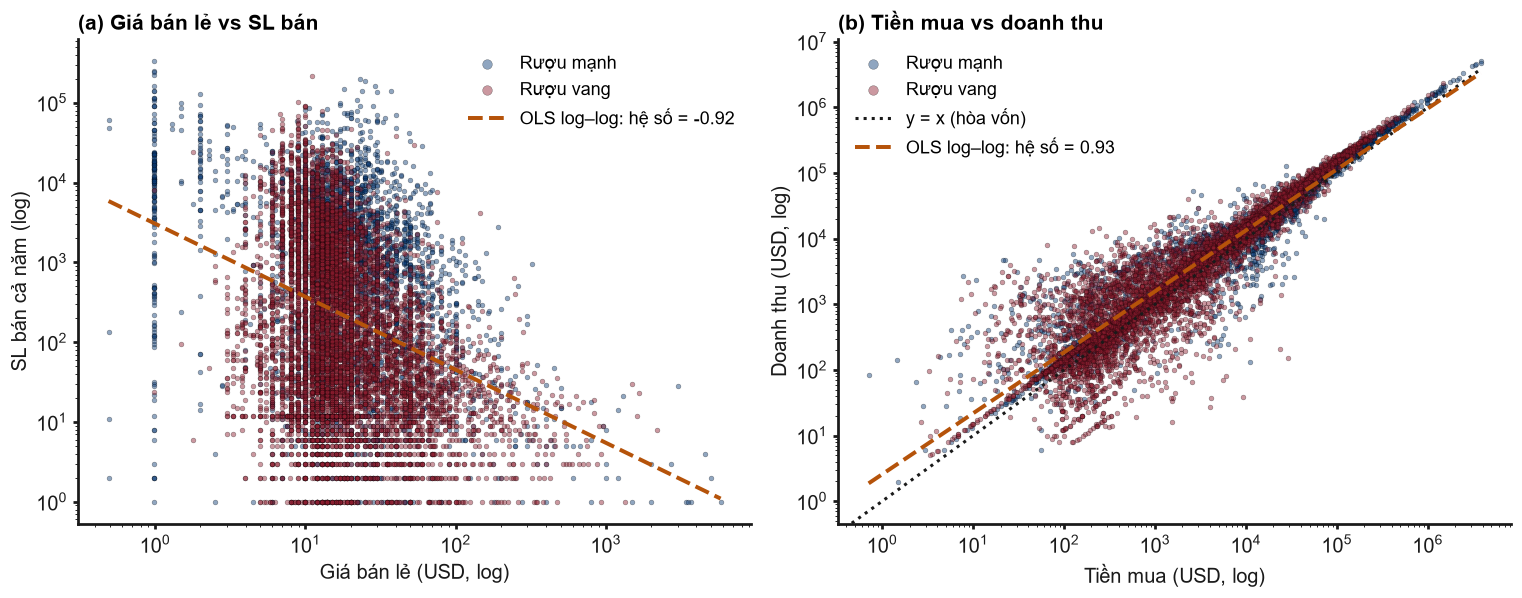

In [5]:
s = vb[(vb["sales_qty"] > 0) & (vb["RetailPrice"] > 0)]
fig, axes = viz.new_figure(1, 2, figsize=(14, 5.6))
for cls, g in s.groupby("ClassName"):
    viz.scatter(axes[0], g["RetailPrice"], g["sales_qty"], color=CLASS_COLORS[cls], size=10, alpha=0.45, label=cls)
    viz.scatter(axes[1], g["purchase_dollars"], g["sales_dollars"], color=CLASS_COLORS[cls], size=10, alpha=0.45, label=cls)
viz.fit_line(axes[0], s["RetailPrice"], s["sales_qty"], log=True, color=PALETTE["orange"])
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].legend(markerscale=2)
viz.label(axes[0], "(a) Giá bán lẻ vs SL bán", "Giá bán lẻ (USD, log)", "SL bán cả năm (log)")
lim = [s["purchase_dollars"].min(), s["purchase_dollars"].max()]
axes[1].plot(lim, lim, color=PALETTE["dark"], ls=":", lw=2, label="y = x (hòa vốn)")
viz.fit_line(axes[1], s["purchase_dollars"], s["sales_dollars"], log=True, color=PALETTE["orange"])
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].legend(markerscale=2)
viz.label(axes[1], "(b) Tiền mua vs doanh thu", "Tiền mua (USD, log)", "Doanh thu (USD, log)")
viz.save_figure(fig, "03_price_qty_purchase_sales")
plt.show()

**Biểu đồ 3.3 — Biên lợi nhuận và vòng quay theo phân khúc giá × nhóm** (`price_band_summary`
+ pivot). Heatmap cho biết phân khúc nào vừa có biên cao vừa quay vòng nhanh.

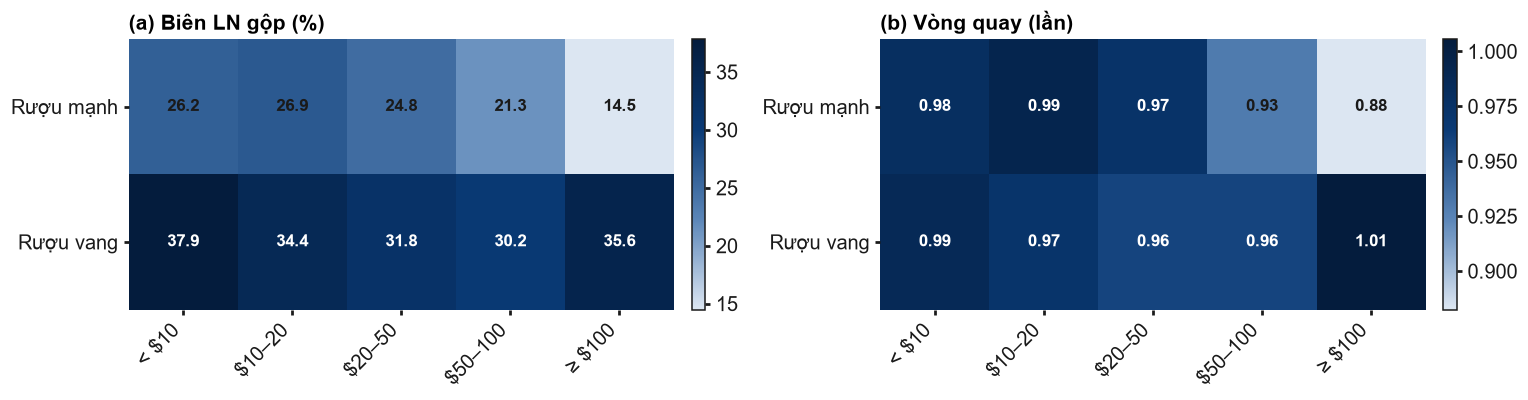

PriceBand,n_brands,sales_qty,sales_dollars,gross_profit,margin_pct,stock_turnover,n_unsold
1. < $10,"2,678","15,080,349","$84,991,145","$29,008,770",34.13,0.98,28
2. $10–20,"4,601","11,564,021","$168,261,943","$50,860,359",30.23,0.98,77
3. $20–50,"2,791","5,838,887","$167,335,370","$43,017,493",25.71,0.97,33
4. $50–100,889,"395,019","$24,824,348","$5,789,963",23.32,0.94,22
5. ≥ $100,491,"39,600","$6,650,146","$1,485,601",22.34,0.92,18


In [6]:
grp = (vb[vb["PriceBand"].notna()].groupby(["ClassName", "PriceBand"])
       .agg(gp=("gross_profit", "sum"), sd=("sales_dollars", "sum"), sq=("sales_qty", "sum"), pq=("purchase_qty", "sum")))
grp["margin"] = grp["gp"] / grp["sd"] * 100
grp["turn"] = grp["sq"] / grp["pq"]
fig, axes = viz.new_figure(1, 2, figsize=(14, 3.8))
for ax, col, title, fmt in [(axes[0], "margin", "(a) Biên LN gộp (%)", "{:.1f}"), (axes[1], "turn", "(b) Vòng quay (lần)", "{:.2f}")]:
    mat = grp[col].unstack("PriceBand")
    mat.columns = [c[3:] for c in mat.columns]
    viz.heatmap(ax, mat, annotate=True, fmt=fmt, fontsize=11)
    viz.label(ax, title)
viz.save_figure(fig, "03_priceband_class_heatmap")
plt.show()
pp.style_table(dl.query("price_band_summary"), money=["sales_dollars", "gross_profit"], num=["n_brands", "sales_qty", "n_unsold"],
               dec=["margin_pct", "stock_turnover"])

## 4. Cấp nhà cung cấp

**Biểu đồ 3.4 — Pareto doanh thu theo NCC** (30 NCC lớn nhất + đường tỷ trọng lũy kế trên
toàn bộ NCC). Kèm chỉ số tập trung Gini và HHI.

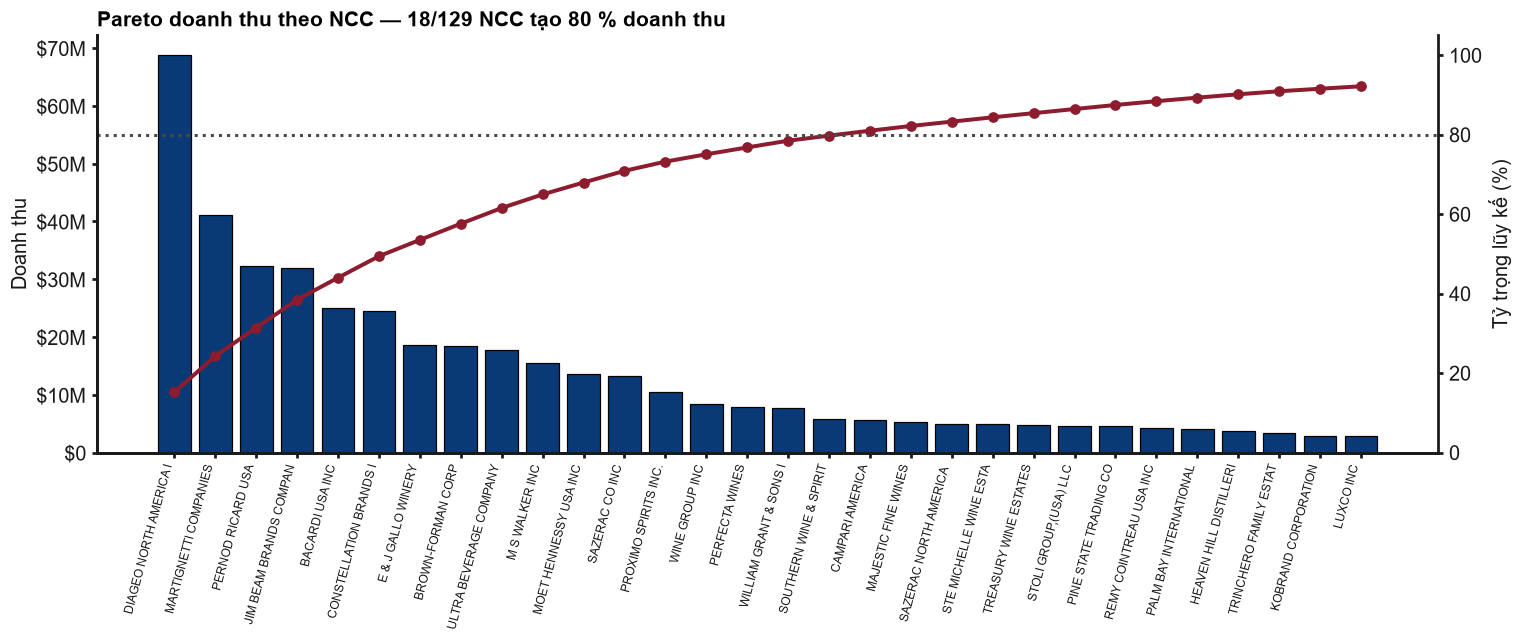

,giá trị
Số NCC,129.00
NCC đạt 80% doanh thu,18.00
Gini doanh thu,0.84
HHI (0–10 000),584.30


In [7]:
v = vendors.sort_values("sales_dollars", ascending=False)
top = v.head(30)
fig, (ax,) = viz.new_figure(figsize=(14, 6))
ax.bar(range(len(top)), top["sales_dollars"], color=PALETTE["blue"], edgecolor="black", linewidth=0.8)
ax.set_xticks(range(len(top)), [n[:22] for n in top["VendorName"]], rotation=75, ha="right", fontsize=8)
viz.fmt_axis(ax, y="money")
ax2 = ax.twinx()
ax2.plot(range(len(top)), top["cum_sales_share_pct"], color=PALETTE["wine"], marker="o", lw=2.6)
ax2.axhline(80, color=PALETTE["gray"], ls=":", lw=2)
ax2.set_ylim(0, 105); ax2.spines["right"].set_visible(True); ax2.set_ylabel("Tỷ trọng lũy kế (%)")
k80 = pp.n_to_reach_share(v["cum_sales_share_pct"], 80)
viz.label(ax, f"Pareto doanh thu theo NCC — {k80}/{len(v)} NCC tạo 80 % doanh thu", None, "Doanh thu")
viz.save_figure(fig, "03_vendor_pareto")
plt.show()
pd.Series({"Số NCC": len(v), "NCC đạt 80% doanh thu": k80,
           "Gini doanh thu": round(pp.gini(v["sales_dollars"]), 3),
           "HHI (0–10 000)": round(pp.hhi(v["sales_share_pct"]), 1)}).to_frame("giá trị")

**Biểu đồ 3.5 — (a) Quy mô NCC vs biên lợi nhuận** (kích thước bong bóng ∝ số sản phẩm) và
**(b) tiền mua vs phí vận chuyển** (log–log; hệ số ≈ 1 ⇒ phí tỷ lệ thuận với tiền mua, < 1 mới là lợi thế
quy mô). Biên ở (a) cắt tại −100 % vì vài NCC rất nhỏ lỗ nặng.

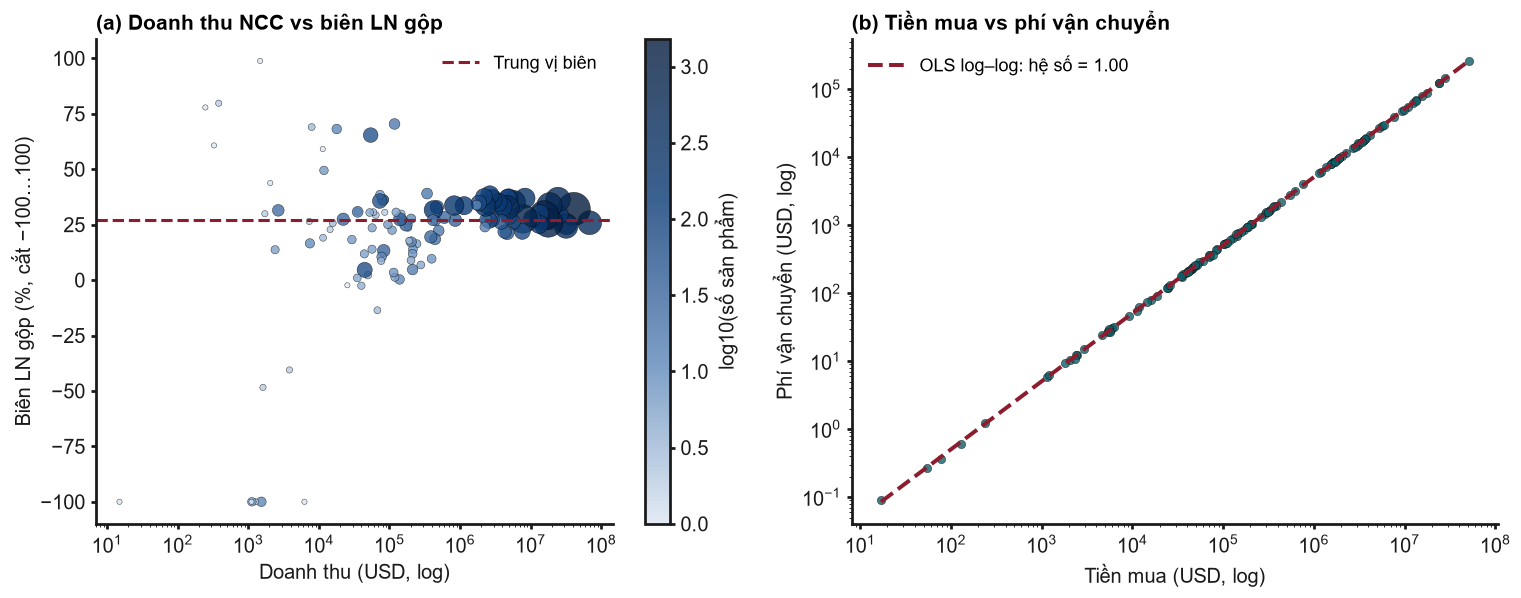

In [8]:
vv = vendors[(vendors["sales_dollars"] > 0) & (vendors["purchase_dollars"] > 0)]
fig, axes = viz.new_figure(1, 2, figsize=(14, 5.6))
sc = viz.scatter(axes[0], vv["sales_dollars"], vv["margin_pct"].clip(-100, 100), size=np.sqrt(vv["n_brands"]) * 12,
                 c=np.log10(vv["n_brands"]), alpha=0.8, log_x=True)
axes[0].axhline(vv["margin_pct"].median(), color=PALETTE["wine"], ls="--", lw=2, label="Trung vị biên")
axes[0].legend()
fig.colorbar(sc, ax=axes[0], label="log10(số sản phẩm)")
viz.label(axes[0], "(a) Doanh thu NCC vs biên LN gộp", "Doanh thu (USD, log)", "Biên LN gộp (%, cắt −100…100)")
ff = vv[vv["freight"] > 0]
viz.scatter(axes[1], ff["purchase_dollars"], ff["freight"], color=PALETTE["teal"], size=30, alpha=0.8, log_x=True, log_y=True)
viz.fit_line(axes[1], ff["purchase_dollars"], ff["freight"], log=True)
axes[1].legend()
viz.label(axes[1], "(b) Tiền mua vs phí vận chuyển", "Tiền mua (USD, log)", "Phí vận chuyển (USD, log)")
viz.save_figure(fig, "03_vendor_scale")
plt.show()

Tương quan Spearman giữa quy mô NCC và các chỉ tiêu hiệu quả (biên, vòng quay, % phí vận
chuyển, lead time, thời gian thanh toán).

In [9]:
vcols = ["sales_dollars", "n_brands", "margin_pct", "stock_turnover", "freight_pct", "avg_lead_days", "avg_pay_days"]
vendors[vcols].corr(method="spearman").loc[["sales_dollars", "n_brands"]]

,sales_dollars,n_brands,margin_pct,stock_turnover,freight_pct,avg_lead_days,avg_pay_days
sales_dollars,1.00,0.87,0.13,0.31,0.09,0.85,0.01
n_brands,0.87,1.00,0.22,0.29,0.08,0.69,0.06


**Biểu đồ 3.6 — Mùa vụ của 8 NCC lớn nhất.** Mỗi hàng chuẩn hóa theo tổng năm của NCC
(% doanh thu năm) để so sánh hình dạng mùa vụ, không bị chi phối bởi quy mô.

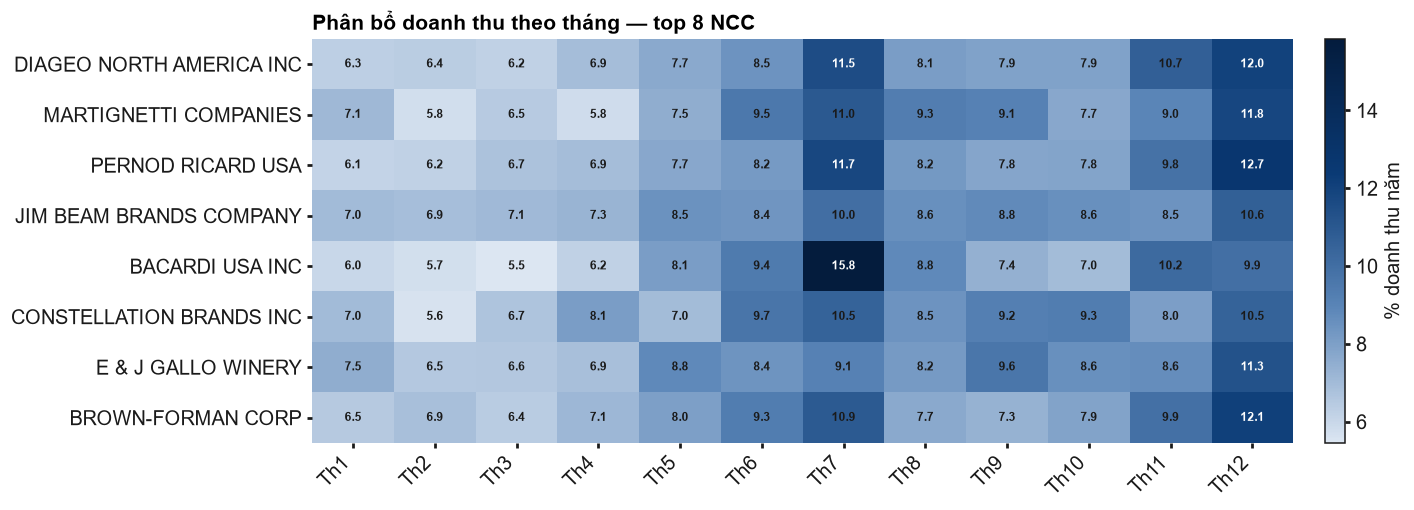

In [10]:
vm = dl.query("vendor_month_sales", top_n=8)
mat = vm.pivot_table(index="VendorName", columns="Month", values="dollars", aggfunc="sum")
mat = mat.loc[vm.drop_duplicates("VendorName").sort_values("sales_rank")["VendorName"]]
mat = mat.div(mat.sum(axis=1), axis=0) * 100
mat.columns = pp.month_label(pd.Series(mat.columns))
mat.index = [n[:28] for n in mat.index]
fig, (ax,) = viz.new_figure(figsize=(13, 4.8))
viz.heatmap(ax, mat, annotate=True, fmt="{:.1f}", cbar_label="% doanh thu năm", fontsize=8)
viz.label(ax, "Phân bổ doanh thu theo tháng — top 8 NCC")
viz.save_figure(fig, "03_vendor_seasonality")
plt.show()

## 5. Mua hàng vs bán hàng theo thời gian

**Biểu đồ 3.7 — Doanh thu bán và tiền mua theo tháng**, cùng tỷ lệ bán/mua theo số lượng
(sell-through). Tỷ lệ > 1 ⇒ tháng đó bán nhiều hơn nhập (rút tồn kho).

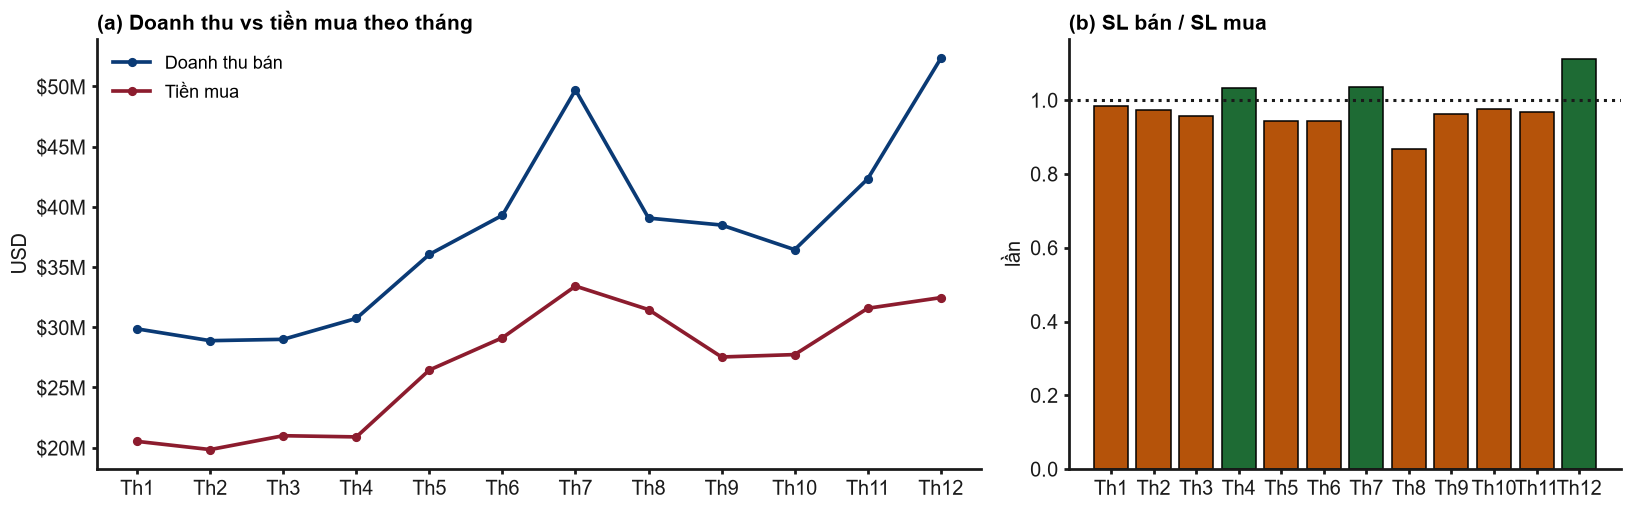

,sales_dollars,purchase_dollars,sell_through
sales_dollars,1.00,0.92,0.44
purchase_dollars,0.92,1.00,0.09
sell_through,0.44,0.09,1.00


In [11]:
x = pp.month_label(monthly["Month"])
fig, axes = viz.new_figure(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
viz.lines(axes[0], x, {"Doanh thu bán": monthly["sales_dollars"], "Tiền mua": monthly["purchase_dollars"]},
          colors=[PALETTE["blue"], PALETTE["wine"]])
viz.fmt_axis(axes[0], y="money")
viz.label(axes[0], "(a) Doanh thu vs tiền mua theo tháng", None, "USD")
axes[1].bar(x, monthly["sell_through"], color=[PALETTE["green"] if t > 1 else PALETTE["orange"] for t in monthly["sell_through"]],
            edgecolor="black", linewidth=1)
axes[1].axhline(1, color=PALETTE["dark"], ls=":", lw=2)
viz.label(axes[1], "(b) SL bán / SL mua", None, "lần")
viz.save_figure(fig, "03_sales_vs_purchases_monthly")
plt.show()
monthly[["Month", "sales_dollars", "purchase_dollars", "sell_through"]].corr(numeric_only=True)

## 6. Cấp cửa hàng

**Biểu đồ 3.8 — (a) Giá trị tồn kho trung bình vs doanh thu cửa hàng** (log–log) và
**(b) doanh thu vs số mặt hàng tồn kho** (độ rộng danh mục).

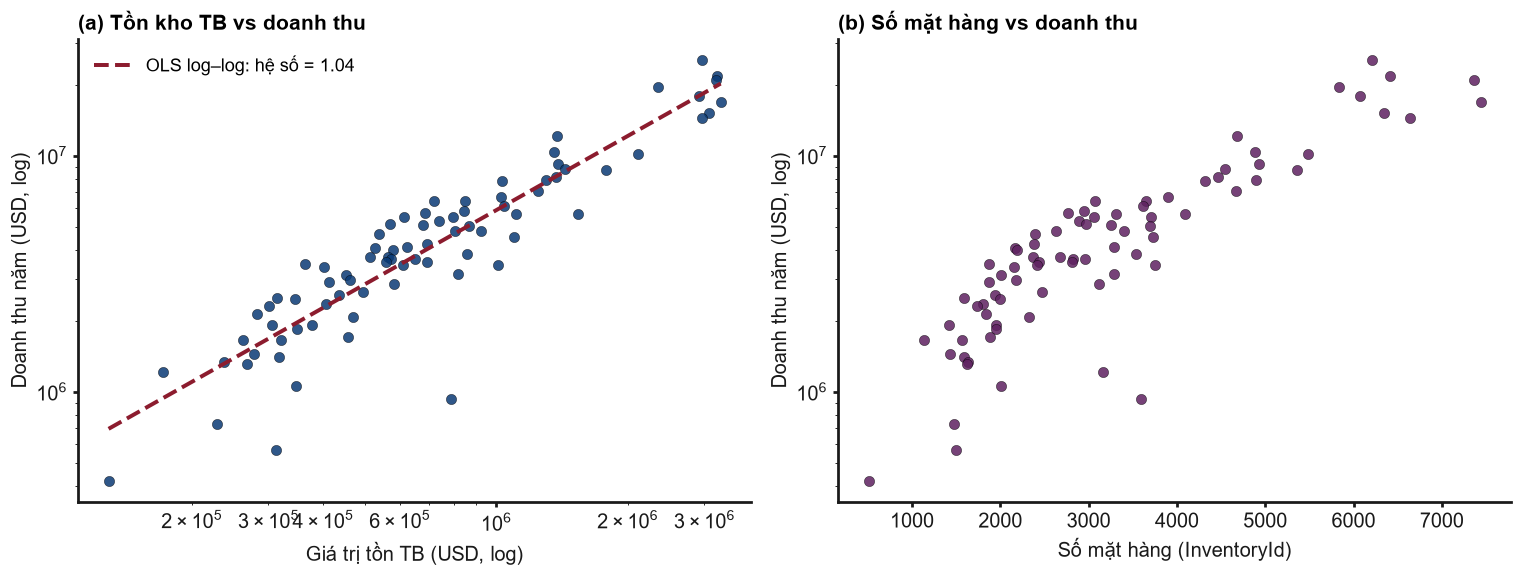

,sales_dollars,purchase_dollars,avg_inv_value,n_items,sales_to_avg_inventory
sales_dollars,1.00,0.99,0.91,0.87,0.35
purchase_dollars,0.99,1.00,0.93,0.89,0.33
avg_inv_value,0.91,0.93,1.00,0.95,0.02
n_items,0.87,0.89,0.95,1.00,0.07
sales_to_avg_inventory,0.35,0.33,0.02,0.07,1.00


In [12]:
st = stores.dropna(subset=["sales_dollars", "begin_value", "end_value"]).copy()
st["avg_inv_value"] = (st["begin_value"] + st["end_value"]) / 2
fig, axes = viz.new_figure(1, 2, figsize=(14, 5.4))
viz.scatter(axes[0], st["avg_inv_value"], st["sales_dollars"], color=PALETTE["blue"], size=45, alpha=0.85, log_x=True, log_y=True)
viz.fit_line(axes[0], st["avg_inv_value"], st["sales_dollars"], log=True)
axes[0].legend()
viz.label(axes[0], "(a) Tồn kho TB vs doanh thu", "Giá trị tồn TB (USD, log)", "Doanh thu năm (USD, log)")
viz.scatter(axes[1], st["n_items"], st["sales_dollars"], color=PALETTE["violet"], size=45, alpha=0.85, log_y=True)
viz.label(axes[1], "(b) Số mặt hàng vs doanh thu", "Số mặt hàng (InventoryId)", "Doanh thu năm (USD, log)")
viz.save_figure(fig, "03_store_inventory_sales")
plt.show()
st[["sales_dollars", "purchase_dollars", "avg_inv_value", "n_items", "sales_to_avg_inventory"]].corr(method="spearman")

**Biểu đồ 3.9 — Heatmap doanh thu cửa hàng × tháng** (20 cửa hàng lớn nhất, chuẩn hóa theo
tổng năm của từng cửa hàng) để xem mùa vụ có đồng nhất giữa các cửa hàng không.

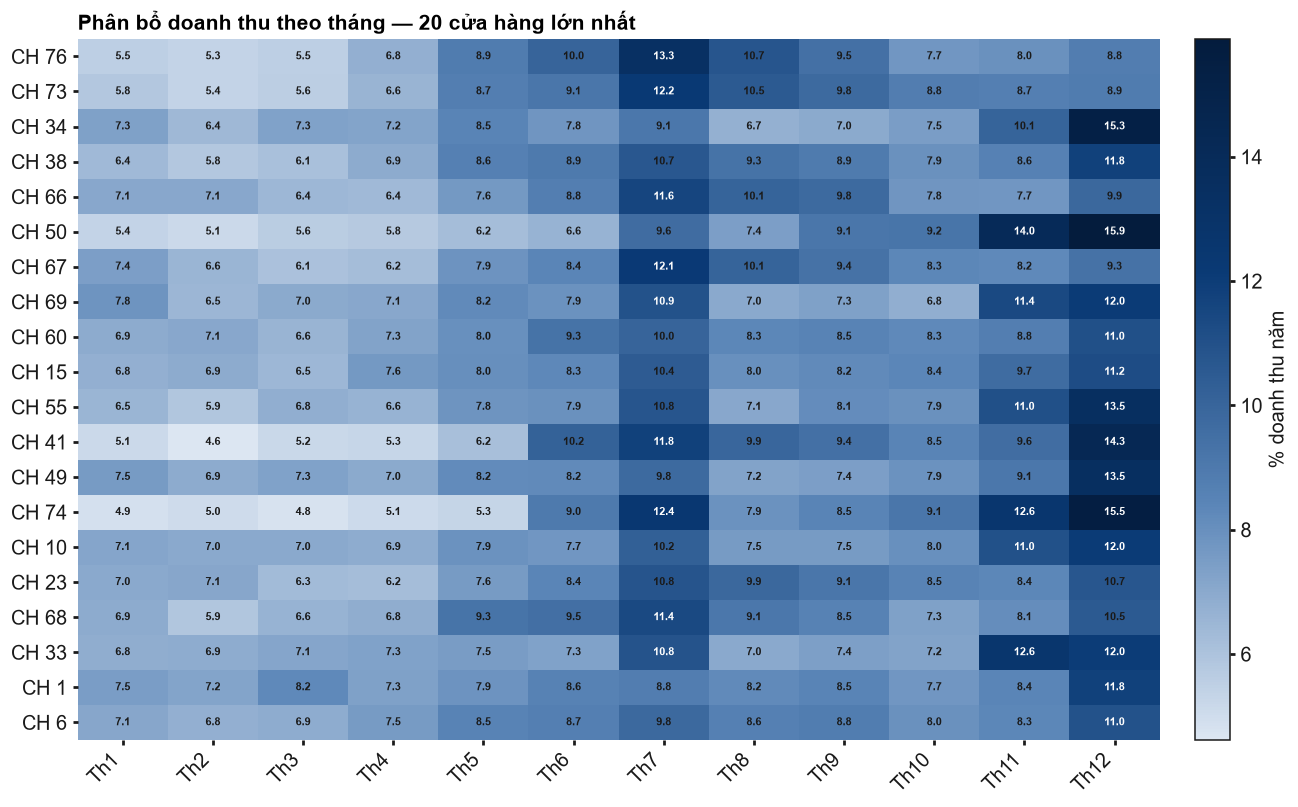

In [13]:
sm = dl.query("store_month_sales")
mat = sm.pivot(index="Store", columns="Month", values="dollars")
mat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index[:20]]
mat = mat.div(mat.sum(axis=1), axis=0) * 100
mat.columns = pp.month_label(pd.Series(mat.columns))
mat.index = [f"CH {s}" for s in mat.index]
fig, (ax,) = viz.new_figure(figsize=(12, 7.5))
viz.heatmap(ax, mat, annotate=True, fmt="{:.1f}", cbar_label="% doanh thu năm", fontsize=7)
viz.label(ax, "Phân bổ doanh thu theo tháng — 20 cửa hàng lớn nhất")
viz.save_figure(fig, "03_store_month_heatmap")
plt.show()

## 7. Cấp đơn hàng (PO)

**Biểu đồ 3.10 — (a) Giá trị hóa đơn vs % phí vận chuyển** và **(b) số dòng hàng trong PO vs
lead time** (boxplot theo nhóm quy mô).

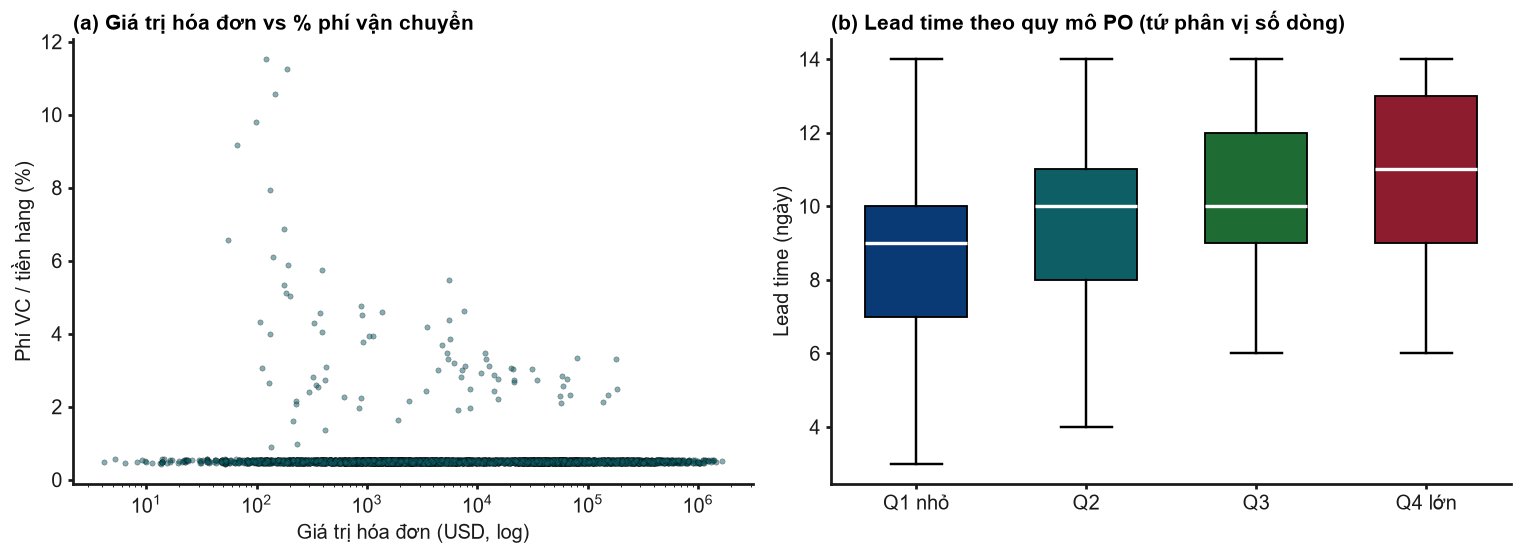

,invoice_dollars,n_lines,freight_pct,lead_days,pay_days
invoice_dollars,1.00,0.98,-0.04,0.40,0.02
n_lines,0.98,1.00,-0.04,0.41,0.02
freight_pct,-0.04,-0.04,1.00,-0.01,-0.00
lead_days,0.40,0.41,-0.01,1.00,-0.02
pay_days,0.02,0.02,-0.00,-0.02,1.00


In [14]:
fig, axes = viz.new_figure(1, 2, figsize=(14, 5.2))
viz.scatter(axes[0], po["invoice_dollars"], po["freight_pct"], color=PALETTE["teal"], size=12, alpha=0.5, log_x=True)
viz.label(axes[0], "(a) Giá trị hóa đơn vs % phí vận chuyển", "Giá trị hóa đơn (USD, log)", "Phí VC / tiền hàng (%)")
po["size_band"] = pd.qcut(po["n_lines"], 4, labels=["Q1 nhỏ", "Q2", "Q3", "Q4 lớn"])
viz.boxplot(axes[1], {str(k): g["lead_days"] for k, g in po.groupby("size_band", observed=True)},
            colors=[PALETTE["blue"], PALETTE["teal"], PALETTE["green"], PALETTE["wine"]])
viz.label(axes[1], "(b) Lead time theo quy mô PO (tứ phân vị số dòng)", None, "Lead time (ngày)")
viz.save_figure(fig, "03_po_relationships")
plt.show()
po[["invoice_dollars", "n_lines", "freight_pct", "lead_days", "pay_days"]].corr(method="spearman")

## 8. Nhận xét

1. **Quy mô quyết định mọi thứ ở cấp sản phẩm:** SL mua, tiền mua, SL bán, doanh thu, số cửa hàng bán và
   phí vận chuyển phân bổ tương quan rất mạnh (ρ ≈ 0,84–0,95). Biên % và vòng quay gần như **độc lập với
   quy mô** (|ρ| < 0,2) nhưng tương quan mạnh với nhau (ρ ≈ 0,89) → sản phẩm quay vòng nhanh là sản phẩm
   có biên cao (vì biên ở đây = (doanh thu − tiền mua)/doanh thu, chịu ảnh hưởng của lượng hàng chưa bán).
2. **Đường cầu dốc xuống:** hệ số log–log giá → SL bán ≈ −0,9 (giá tăng 10 % ↔ SL bán giảm ~9 %, *tương
   quan chứ chưa phải nhân quả*). Tiền mua ↔ doanh thu bám sát đường hòa vốn y = x với hệ số ≈ 0,93.
3. **Phân khúc giá:** biên giảm đều từ ~34 % (< 10 USD) xuống ~21 % (≥ 100 USD); vòng quay cũng giảm
   theo giá. Rượu vang có biên cao hơn rượu mạnh ở mọi phân khúc.
4. **Tập trung NCC cao:** 18/129 NCC tạo 80 % doanh thu; NCC lớn nhất (Diageo) ~15 %, top 10 ~65 %;
   Gini ≈ 0,84, HHI ≈ 584 (thị trường *không tập trung* theo ngưỡng chống độc quyền < 1 500, nhưng phụ
   thuộc rõ vào nhóm đầu). **Không có lợi thế quy mô về vận chuyển:** hệ số log–log tiền mua → phí vận
   chuyển ≈ 1,00 và % phí vận chuyển không tương quan với quy mô NCC (ρ ≈ 0,09) — mọi NCC đều chịu ~0,5 %.
   *(Nếu nối hóa đơn thẳng theo `PONumber` sẽ ra hệ số giả ≈ 0,71 và ρ ≈ −0,66, do 1 336 hóa đơn bị xáo
   trộn số PO — xem NB01 §6.1.)* NCC lớn có lead time (đặt → nhận đủ) **dài hơn** (ρ ≈ +0,85) vì PO lớn
   giao cho nhiều cửa hàng theo nhiều đợt.
5. **Mua theo sát bán:** tiền mua và doanh thu hàng tháng cùng nhịp mùa vụ; tỷ lệ SL bán/SL mua > 1 ở
   tháng 4, 7, 12 (rút tồn kho vào mùa cao điểm) và thấp nhất tháng 8 (nhập bù sau đỉnh tháng 7).
6. **Cửa hàng:** doanh thu tương quan rất mạnh với giá trị tồn kho (ρ ≈ 0,88–0,92) và số mặt hàng
   (ρ ≈ 0,87); hình dạng mùa vụ gần như giống nhau giữa 20 cửa hàng lớn nhất → mùa vụ là yếu tố toàn
   chuỗi, không riêng địa phương.
7. **PO:** % phí vận chuyển gần như **không phụ thuộc** giá trị PO (ρ ≈ −0,04) — phí tỷ lệ thuận với tiền
   hàng ở mức ~0,5 %. PO giá trị lớn / nhiều dòng hàng mất lâu hơn để nhận đủ hàng (ρ ≈ +0,40).